# clustercert tour

You have a bond list for an exact-diagonalization cluster, and someone claims it is a periodic cluster of some lattice. Is it? The first two sections are all you need to use the tool; the rest open it up step by step. Every cell runs in a second or two.

## 1. Is this bond list really kagome?

Here is a 12-site bond list that claims to be a kagome cluster with periodic boundary conditions. Pass it to `certify` with the lattice's name:

YES: periodic kagome cluster, periods [[2, 0], [0, 2]]
  periods (in primitive vectors -> Cartesian):
    (2, 0) -> (2, 0)
    (0, 2) -> (1, 1.732)
  site map, your label -> (unit cell, sublattice):
    0 -> (0, 1), 1
    1 -> (0, 1), 0
    2 -> (1, 1), 1
    3 -> (1, 1), 0
    4 -> (0, 1), 2
    5 -> (1, 1), 2
    6 -> (1, 0), 1
    7 -> (1, 0), 0
    8 -> (0, 0), 1
    9 -> (0, 0), 0
    10 -> (1, 0), 2
    11 -> (0, 0), 2
  4 allowed momenta (in reciprocal primitive vectors): (0, 0), (0, 1/2), (1/2, 0), (1/2, 1/2)


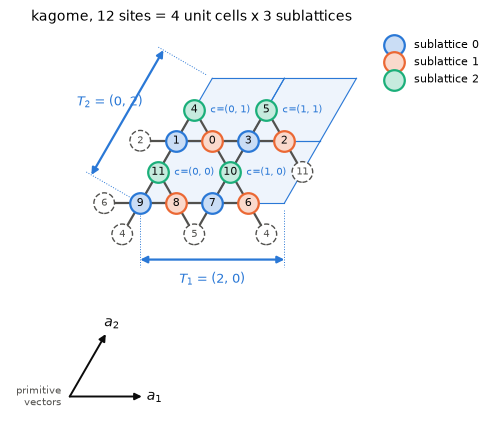

In [1]:
import clustercert as cc

edges = [(0, 1), (0, 3), (0, 4), (0, 10), (1, 2), (1, 4), (1, 11), (2, 3), (2, 5), (2, 11), (3, 5), (3, 10),
         (4, 6), (4, 9), (5, 7), (5, 8), (6, 7), (6, 9), (6, 10), (7, 8), (7, 10), (8, 9), (8, 11), (9, 11)]
result = cc.certify(edges, 'kagome')
print(cc.summary(result))
cc.plot(result, details=True);

**Yes.** The drawing is your cluster with your own labels. Each shaded tile is one unit cell of the kagome lattice, labelled with its coordinates c in units of the primitive vectors a₁ and a₂ (the arrows). Each site is coloured by its *sublattice*, one of the three sites of a unit cell. A bond that wraps around the boundary ends on a dashed circle labelled with the site it wraps to.

This is exactly the *site map* printed above, and the site map is the certificate: site 9 is sublattice 0 of unit cell (0, 0), and so on. The *periods* say which translations the boundary conditions identify. You don't have to trust the search: fold the kagome lattice by these periods and compare bond by bond.

In [2]:
folded = cc.cluster(cc.KAGOME, result['periods'])     # kagome folded by the periods
site = result['sites']
print({frozenset((site[i], site[j])) for i, j in edges} == {frozenset(e) for e in folded.edges})

True


## 2. A counterexample

A second bond list. It passes every local check: 12 sites, 24 bonds, 4 neighbours per site, and each site in exactly two triangles, just as in kagome.

In [3]:
import networkx as nx

impostor = [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 7), (1, 9), (2, 8), (2, 11), (3, 4), (3, 5), (3, 6),
            (4, 9), (4, 10), (5, 6), (5, 7), (5, 8), (6, 10), (6, 11), (7, 8), (7, 9), (8, 11), (9, 10), (10, 11)]
for name, bonds in (('kagome  ', edges), ('impostor', impostor)):
    g = nx.Graph(bonds)
    print(name, '| neighbours per site:', set(dict(g.degree).values()),
          '| triangles per site:', set(nx.triangles(g).values()))

print(cc.summary(cc.certify(impostor, 'kagome')))

kagome   | neighbours per site: {4} | triangles per site: {2}
impostor | neighbours per site: {4} | triangles per site: {2}
NO: not a periodic kagome cluster: none of the 7 possible supercells of 4 unit cells matches


**No.** There are exactly 7 ways to fold kagome into 12 sites, and none of them gives this graph. Local checks cannot see the difference; only a global one can.

That is the whole tool: `cc.certify(edges, name)` with any built-in lattice (square, triangular, honeycomb, kagome, checkerboard, cubic, bcc, fcc, diamond, pyrochlore), and `cc.summary` to read the result. The sections below explain the inputs, then what else the result tells you.

## 3. What goes in

A **lattice** is described by one unit cell: its primitive vectors, its sites (*sublattices* 0, 1, …, each with a position), and its bonds. A bond `(a, b, t)` joins sublattice `a` in unit cell `c` to sublattice `b` in unit cell `c + t`, for every integer vector `c`. `plot_lattice` draws one unit cell with every bond numbered, and `describe()` lists the same in text:

kagome: 2D, 3 sublattice(s) per unit cell, 6 bonds per unit cell
  primitive vector a1 = (1, 0)
  primitive vector a2 = (0.5, 0.866)
  sublattice 0 at (0, 0)
  sublattice 1 at (0.5, 0)
  sublattice 2 at (0.25, 0.433)
  bond (0, 1, (-1, 0)): sublattice 0 in unit cell c -- sublattice 1 in unit cell c + (-1, 0), length 0.5
  bond (0, 1, (0, 0)): sublattice 0 in unit cell c -- sublattice 1 in unit cell c + (0, 0), length 0.5
  bond (0, 2, (0, -1)): sublattice 0 in unit cell c -- sublattice 2 in unit cell c + (0, -1), length 0.5
  bond (0, 2, (0, 0)): sublattice 0 in unit cell c -- sublattice 2 in unit cell c + (0, 0), length 0.5
  bond (1, 2, (0, 0)): sublattice 1 in unit cell c -- sublattice 2 in unit cell c + (0, 0), length 0.5
  bond (1, 2, (1, -1)): sublattice 1 in unit cell c -- sublattice 2 in unit cell c + (1, -1), length 0.5


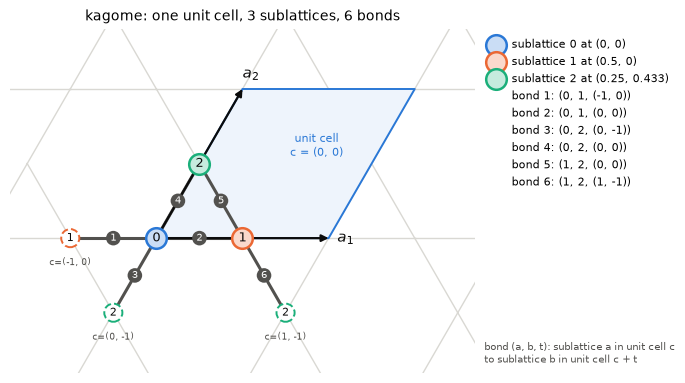

In [4]:
cc.plot_lattice(cc.KAGOME)
print(cc.KAGOME.describe())

**Periods** set the boundary conditions. They are integer vectors in units of the primitive vectors: the rows of the matrix below are T₁ = 2a₁ and T₂ = 2a₂. Folding identifies any two sites that differ by a combination of the periods. What is left is the **supercell**: here 2 × 2 = 4 unit cells, so 4 × 3 = 12 sites. `cc.cluster` does the folding, and `cc.plot` shows it. The periods are the blue arrows along the supercell; each shaded tile is one unit cell c; and the dashed circles are the sites a bond reaches across the boundary, which the periods fold back into the supercell.

12 sites, 24 bonds


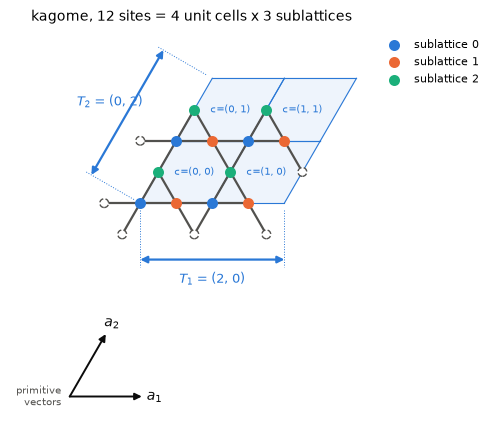

In [5]:
periods = [[2, 0], [0, 2]]          # T1 = 2 a1 and T2 = 2 a2
folded = cc.cluster(cc.KAGOME, periods)
print(folded.number_of_nodes(), 'sites,', folded.number_of_edges(), 'bonds')
cc.plot(folded, details=True);

A **cluster** is your bond list: pairs of site labels, with no geometry, as in section 1. The folded lattice above is a cluster whose sites happen to be labelled by (unit cell, sublattice):

In [6]:
print('neighbours of sublattice 0 in unit cell (0, 0):', sorted(folded[((0, 0), 0)]))

neighbours of sublattice 0 in unit cell (0, 0): [((0, 0), 1), ((0, 0), 2), ((0, 1), 2), ((1, 0), 1)]


`certify` runs this backwards: given only your bond list, it tries every possible set of periods for that number of sites, and looks for one that folds the lattice into your graph.

## 4. One graph, several supercells

With `find_all=True`, `certify` keeps going after the first match. For our 12-site list, four supercells give the same graph. Two are drawn below with `cc.plot`.

every matching supercell: [((2, 0), (0, 2)), ((2, 1), (0, 2)), ((1, 1), (0, 4)), ((1, 2), (0, 4))]


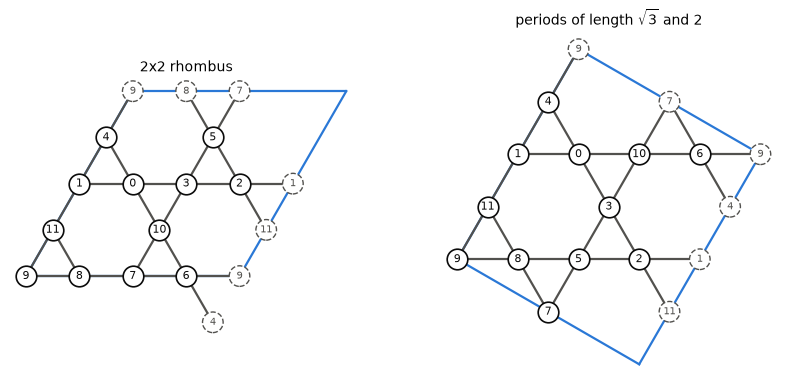

In [7]:
import matplotlib.pyplot as plt
import numpy as np

every = cc.certify(edges, 'kagome', find_all=True)
print('every matching supercell:', every['matching'])
rhombus = cc.certify(edges, 'kagome', periods=[[2, 0], [0, 2]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
cc.plot(rhombus, ax=axes[0], title='2x2 rhombus')
cc.plot(every, ax=axes[1], title='periods of length $\\sqrt{3}$ and 2')
plt.show()

The two clusters look different, but they are the same graph, so a nearest-neighbour Hamiltonian has the same spectrum on both. What differs is the translation group, and so the momentum labels. Each supercell has 4 allowed momenta, but they are different momenta:

In [8]:
for periods in ([[2, 0], [0, 2]], every['periods']):
    print(periods, '->', [tuple(map(str, k)) for k in cc.momenta(periods)])

[[2, 0], [0, 2]] -> [('0', '0'), ('0', '1/2'), ('1/2', '0'), ('1/2', '1/2')]
((2, 1), (0, 2)) -> [('0', '0'), ('1/4', '1/2'), ('1/2', '0'), ('3/4', '1/2')]


## 5. Common mistakes

A bond wrapped to the wrong site: every site keeps 4 neighbours, but the graph is no longer kagome. A missing wrap-around bond: the degree check catches it at once, with a hint.

In [9]:
import random

wrong = nx.Graph(edges)
rng = random.Random(1)
while True:     # swap the ends of two bonds: every site keeps 4 neighbours
    (a, b), (c, d) = rng.sample(sorted(wrong.edges), 2)
    if len({a, b, c, d}) == 4 and not wrong.has_edge(a, d) and not wrong.has_edge(c, b):
        break
wrong.remove_edges_from([(a, b), (c, d)])
wrong.add_edges_from([(a, d), (c, b)])
print('rewired:', cc.certify(wrong, 'kagome')['reason'])
print('missing:', cc.certify(edges[1:], 'kagome')['reason'])

rewired: not a periodic kagome cluster: none of the 7 possible supercells of 4 unit cells matches
missing: degrees [3, 4], but every kagome site has [4] (sites with too few bonds: open boundary or a missing wrap-around bond?)


## 6. Further-neighbour bonds

With a J₂ term, the J₁ graph is no longer the whole Hamiltonian. Section 4 showed that four supercells give our J₁ graph. Do they also give the same J₂ bonds? Pass both bond lists, keyed by neighbour shell, and `certify` reports on every supercell. Here the J₂ list is the second-neighbour bonds of the 2×2 rhombus.

YES: periodic kagome cluster with bond families 1, 2, periods [[2, 0], [0, 2]]
  supercell [[2, 0], [0, 2]]: matches
  supercell [[2, 1], [0, 2]]: family 2 bonds close on themselves or double up in this supercell
  supercell [[1, 1], [0, 4]]: family 2 bonds close on themselves or double up in this supercell
  supercell [[1, 2], [0, 4]]: family 2 bonds close on themselves or double up in this supercell
  periods (in primitive vectors -> Cartesian):
    (2, 0) -> (2, 0)
    (0, 2) -> (1, 1.732)
  site map: 12 sites, in result['sites']
  4 allowed momenta (in reciprocal primitive vectors): (0, 0), (0, 1/2), (1/2, 0), (1/2, 1/2)


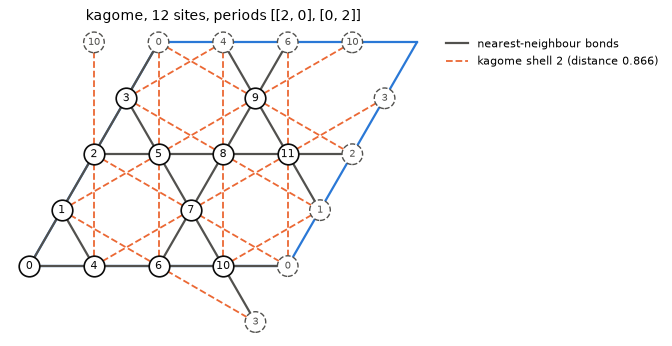

In [10]:
j2 = cc.read_edges('clusters/kagome_12_j2.txt')     # one bond per line: "i j"
both = cc.certify({1: edges, 2: j2}, 'kagome')
print(cc.summary(both, max_sites=0))

cc.plot(both, further=cc.neighbour_shell(cc.KAGOME, 2))
plt.show()

Only the rhombus can host J₂. In the other three supercells, two J₂ bonds fold onto the same pair of sites, so a J₁–J₂ model on those supercells is not the kagome J₁–J₂ model.

If you only have J₁ bonds, `bonds` generates the matching J₂ bonds in your own site labels. Ask for them in the most compact supercell, which is the one `find_all=True` keeps, and you are told which supercell to use instead:

In [11]:
shell2 = cc.neighbour_shell(cc.KAGOME, 2)
try:
    cc.bonds(every, shell2)
except ValueError as error:
    print(error)
generated = cc.bonds(cc.certify(edges, 'kagome', periods=[[2, 0], [0, 2]]), shell2)
print('same as the J2 file:', sorted(generated) == sorted(j2))

kagome shell 2 (distance 0.866) bonds close on themselves or double up in this supercell; the same graph also comes from supercells where they do not, with periods [[[2, 0], [0, 2]]]: pick one with certify(..., periods=...)
same as the J2 file: True


A wrongly wrapped J₂ bond is caught even when every site keeps its four J₂ neighbours:

In [12]:
taken = {frozenset(e) for e in edges + j2}
rng = random.Random(0)
while True:     # swap the ends of two J2 bonds
    (a, b), (c, d) = rng.sample(j2, 2)
    if len({a, b, c, d}) == 4 and not {frozenset((a, d)), frozenset((c, b))} & taken:
        break
wrong_j2 = [e for e in j2 if e not in ((a, b), (c, d))] + [(a, d), (c, b)]
print(cc.certify({1: edges, 2: wrong_j2}, 'kagome')['reason'])

family 1 forms a periodic kagome cluster (4 matching supercells), but in no supercell do the bonds of family 2 match as listed


### Up to J₃

A distance shell can mix inequivalent bonds. Kagome's third shell joins sites along a straight line (`'3a'`, 2 J₁ steps) and across a hexagon (`'3b'`, 3 J₁ steps). The BFG model ([Balents, Fisher and Girvin, arXiv:cond-mat/0110005](https://arxiv.org/abs/cond-mat/0110005); [Phys. Rev. B 65, 224412 (2002)](https://doi.org/10.1103/PhysRevB.65.224412)) has J₁, J₂ and only the across-hexagon J₃. `bond_families` gives each family separately:

In [13]:
families = cc.bond_families(cc.KAGOME, 3)
for key, lattice in families.items():
    print(f'{key!s:3}', lattice.name, '| bonds per site:', lattice.degrees()[0])

1   kagome | bonds per site: 4
2   kagome shell 2 (distance 0.866) | bonds per site: 4
3a  kagome J3a (distance 1, 2 J1 steps, 1 shortest path) | bonds per site: 4
3b  kagome J3b (distance 1, 3 J1 steps, 2 shortest paths) | bonds per site: 2


Which kagome clusters can host the BFG bonds? For each supercell that gives the J₁ graph, check that the J₂ and across-hexagon J₃ bonds neither double up nor land on each other. On the 36-site cluster, generate them with `bonds` and certify all three families together:

kagome_12: 0 of 4 supercells host J1, J2 and J3b


kagome_27: 1 of 1 supercells host J1, J2 and J3b


kagome_36: 1 of 1 supercells host J1, J2 and J3b
YES: periodic kagome cluster with bond families 1, 2, 3b, periods [[2, 2], [0, 6]]
  periods (in primitive vectors -> Cartesian):
    (4, -2) -> (3, -1.732)
    (2, 2) -> (3, 1.732)
  site map: 36 sites, in result['sites']
  12 allowed momenta (in reciprocal primitive vectors): (0, 0), (0, 1/2), (1/6, 1/3), (1/6, 5/6), (1/3, 1/6), (1/3, 2/3), (1/2, 0), (1/2, 1/2), (2/3, 1/3), (2/3, 5/6), (5/6, 1/6), (5/6, 2/3)


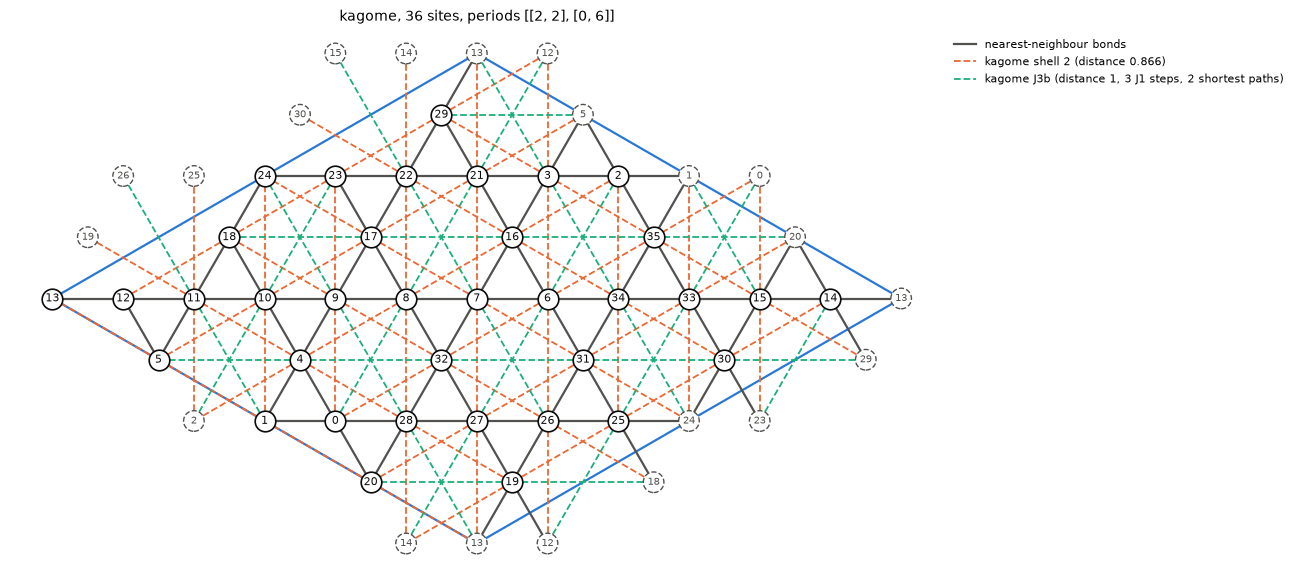

In [14]:
bfg = {1: families[1], 2: families[2], '3b': families['3b']}
for name in ('kagome_12', 'kagome_27', 'kagome_36'):
    r = cc.certify(cc.read_edges(f'clusters/{name}.txt'), 'kagome', find_all=True)
    clean = []
    for h in r['matching']:
        folded = [cc.cluster(m, h) for m in bfg.values()]
        pairs = [frozenset(e) for g in folded if g is not None for e in g.edges]
        if all(g is not None for g in folded) and len(pairs) == len(set(pairs)):
            clean.append(h)
    print(f'{name}: {len(clean)} of {len(r["matching"])} supercells host J1, J2 and J3b')

j1 = cc.read_edges('clusters/kagome_36.txt')
r36 = cc.certify(j1, 'kagome')
bonds = {1: j1, 2: cc.bonds(r36, families[2]), '3b': cc.bonds(r36, families['3b'])}
print(cc.summary(cc.certify(bonds, 'kagome'), max_sites=0))
fig, ax = plt.subplots(figsize=(13, 7))
cc.plot(r36, further=[families[2], families['3b']], ax=ax)
plt.show()

## 7. A standard 3D cluster: 16-site pyrochlore

The conventional cubic cell with periodic boundaries, as used in the exact diagonalization of [Wei and Curnoe, arXiv:2208.06937](https://arxiv.org/abs/2208.06937); [J. Phys.: Condens. Matter 35, 295802 (2023)](https://doi.org/10.1088/1361-648X/acccc8). The most compact matching supercell is the cubic cell itself, and the cluster contains Γ and the three X points of the FCC Brillouin zone.

YES: periodic pyrochlore cluster, periods [[1, 1, 1], [0, 2, 0], [0, 0, 2]]
  periods (in primitive vectors -> Cartesian):
    (1, 1, -1) -> (0, 0, 1)
    (1, -1, 1) -> (0, 1, 0)
    (-1, 1, 1) -> (1, 0, 0)
  4 supercells give this same graph; the periods shown are one of them
  site map, your label -> (unit cell, sublattice):
    0 -> (0, 1, 1), 2
    1 -> (0, 1, 0), 1
    2 -> (0, 0, 1), 0
    3 -> (0, 0, 0), 3
    ... (16 sites in all)
  4 allowed momenta (in reciprocal primitive vectors): (0, 0, 0), (0, 1/2, 1/2), (1/2, 0, 1/2), (1/2, 1/2, 0)
momenta / 2pi: [[0.0, 0.0, 0.0], [1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]


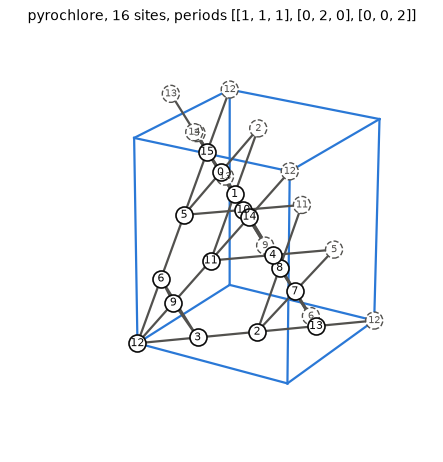

In [15]:
r16 = cc.certify(cc.read_edges('clusters/pyrochlore_16.txt'), 'pyrochlore', find_all=True)
print(cc.summary(r16, max_sites=4))
frac, k = cc.momenta(r16['periods'], cc.PYROCHLORE)
print('momenta / 2pi:', (k / (2*np.pi)).round(3).tolist())
cc.plot(r16)
plt.show()

Does it host J₂? In none of its four supercells do the second-neighbour bonds exist, so the 16-site cluster has no well-defined J₁–J₂ model. The 32-site cluster has exactly one supercell that does:

In [16]:
shell2 = cc.neighbour_shell(cc.PYROCHLORE, 2)
for name in ('pyrochlore_16', 'pyrochlore_32'):
    r = cc.certify(cc.read_edges(f'clusters/{name}.txt'), 'pyrochlore', find_all=True)
    clean = []
    for h in r['matching']:     # J2 bonds must neither double up nor fold onto J1 bonds
        g1, g2 = cc.cluster(cc.PYROCHLORE, h), cc.cluster(shell2, h)
        if g2 is not None and not {frozenset(e) for e in g1.edges} & {frozenset(e) for e in g2.edges}:
            clean.append(h)
    print(f'{name}: {len(r["matching"])} supercells give the J1 graph, {len(clean)} also have clean J2 bonds {clean}')

pyrochlore_16: 4 supercells give the J1 graph, 0 also have clean J2 bonds []


pyrochlore_32: 10 supercells give the J1 graph, 1 also have clean J2 bonds [((2, 0, 0), (0, 2, 0), (0, 0, 2))]


## 8. Which clusters contain a given momentum?

A common ED question: does the cluster contain the K point of the triangular lattice? In units of the reciprocal primitive vectors, K is (2/3, 1/3) (or (1/3, 2/3)).

In [17]:
from fractions import Fraction as F

K = {(F(2, 3), F(1, 3)), (F(1, 3), F(2, 3))}
for periods in ([[3, 0], [0, 3]], [[4, 0], [0, 4]], [[3, 0], [0, 6]], [[4, 2], [-2, 4]], [[6, 0], [0, 6]]):
    n = len(cc.momenta(periods))
    print(f'{n:2d} sites, periods {periods}: contains K = {bool(K & set(cc.momenta(periods)))}')

 9 sites, periods [[3, 0], [0, 3]]: contains K = True
16 sites, periods [[4, 0], [0, 4]]: contains K = False
18 sites, periods [[3, 0], [0, 6]]: contains K = True
20 sites, periods [[4, 2], [-2, 4]]: contains K = False
36 sites, periods [[6, 0], [0, 6]]: contains K = True


## 9. Your own lattice

For a lattice that is not built in, describe one unit cell: either list its bonds in a `cc.Lattice`, or give its geometry as here. The Lieb lattice (the CuO₂ plane) has one corner site and two edge-centre sites per square cell. Below, a 3×3 cluster is scrambled and then recognised.

YES: periodic Lieb cluster, periods [[3, 0], [0, 3]]
  periods (in primitive vectors -> Cartesian):
    (3, 0) -> (3, 0)
    (0, 3) -> (0, 3)
  site map: 27 sites, in result['sites']
  9 allowed momenta (in reciprocal primitive vectors): (0, 0), (0, 1/3), (0, 2/3), (1/3, 0), (1/3, 1/3), (1/3, 2/3), (2/3, 0), (2/3, 1/3), (2/3, 2/3)


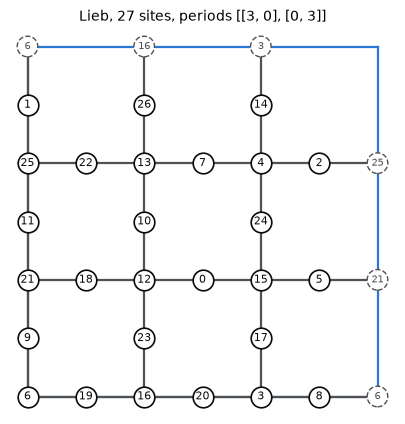

In [18]:
lieb = cc.lattice_from_geometry('Lieb', vectors=[[1, 0], [0, 1]], positions=[[0, 0], [0.5, 0], [0, 0.5]],
                                bond_length=0.5)
g = cc.cluster(lieb, [[3, 0], [0, 3]])
labels = list(range(g.number_of_nodes()))
random.Random(2).shuffle(labels)
scrambled = [(labels[i], labels[j]) for i, j in nx.convert_node_labels_to_integers(g).edges]
recognised = cc.certify(scrambled, lieb)
print(cc.summary(recognised, lieb, max_sites=0))
cc.plot(recognised, lieb)
plt.show()

For the proofs (why the list of candidate supercells is complete, and why a *yes* needs no trust in the search), see [`docs/METHOD.md`](../docs/METHOD.md).